# Predicting purchase intent of online-shop sessions

**ML Zoomcamp midterm project.** An online shop wants to know, while a visitor is still browsing,
whether the session is likely to end in a purchase. This notebook builds and evaluates a binary
classifier that scores each session with a purchase probability. Sessions above a decision
threshold trigger a sales intervention (proactive chat or a nudge); the threshold is chosen from
business costs, not by default. The full business case is in `project-info/business-case.md`.

**Dataset:** [Online Shoppers Purchasing Intention Dataset](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset),
UCI Machine Learning Repository, DOI [10.24432/C5F88Q](https://doi.org/10.24432/C5F88Q)
(Sakar, C. & Kastro, Y., 2018). 12,330 sessions, 18 attributes, licensed CC BY 4.0.
The class is `revenue`: 1,908 sessions ended with a purchase (15.5%), 10,422 did not.

**Plan of the notebook:** cleaning → EDA → stratified train/test split → model comparison
(logistic regression, decision tree, random forest, XGBoost, 5-fold CV) → tuning →
the `PageValues` experiment → class-weight check → cost-based threshold → final test-set check.
All random seeds are fixed at 42.

## 1. Load and inspect

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import xgboost
from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, mutual_info_score

print('sklearn', sklearn.__version__, '| xgboost', xgboost.__version__,
      '| pandas', pd.__version__, '| numpy', np.__version__)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# fixed colors for the two classes, used in every chart (CVD-checked pair)
C_NO = '#4C72B0'   # no purchase
C_YES = '#DD8452'  # purchase
CLASS_PALETTE = {0: C_NO, 1: C_YES}

df = pd.read_csv('data/online_shoppers_intention.csv')
print('rows:', len(df), '| columns:', df.shape[1])
df.head()

sklearn 1.9.1 | xgboost 3.4.1 | pandas 3.1.1 | numpy 2.5.4
rows: 12330 | columns: 18


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [2]:
print(df.dtypes.to_string())

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool


In [3]:
print('missing values per column:')
print(df.isna().sum()[df.isna().sum() > 0].to_string() if df.isna().sum().sum() else 'none — dataset is complete')
print()
df.describe().T[['min', 'max', 'mean']].round(3)

missing values per column:
none — dataset is complete



,min,max,mean
Administrative,0.0,27.000,2.315
Administrative_Duration,0.0,3398.750,80.819
Informational,0.0,24.000,0.504
Informational_Duration,0.0,2549.375,34.472
ProductRelated,0.0,705.000,31.731
ProductRelated_Duration,0.0,63973.522,1194.746
BounceRates,0.0,0.200,0.022
ExitRates,0.0,0.200,0.043
PageValues,0.0,361.764,5.889
SpecialDay,0.0,1.000,0.061


## 2. Cleaning and standardization

The raw file is fairly clean (no missing values), but it still needs standardization:

- **Column names** are lowercased with spaces replaced by underscores. The raw headers are
  CamelCase, so lowercase names collapse (`PageValues` -> `pagevalues`, `SpecialDay` ->
  `specialday`, `VisitorType` -> `visitortype`, `OperatingSystems` -> `operatingsystems`);
  every feature list below uses exactly these names, and `train.py`/`predict.py` apply the
  identical rule.
- **String values** (`Month`, `VisitorType`) are lowercased and spaces are replaced with underscores.
- **`June` → `jun`**: every other month is a 3-letter label (`may`, `nov`, ...), so the 4-letter
  `June` is a consistency bug. We normalize it to `jun`.
- **`OperatingSystems`, `Browser`, `Region`, `TrafficType`** are integer *codes*, not quantities
  (OS "8" is not "more" than OS "1"). They are converted to strings so they get one-hot encoded.
- **`Weekend`** (bool) stays as a 0/1 numeric flag; **`Revenue`** (bool) becomes the 0/1 target.

In [4]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

# standardize string values: lowercase, spaces -> underscores
categorical_string_cols = [
    c for c in df.columns
    if df[c].dtype == 'object' or pd.api.types.is_string_dtype(df[c])
]
for c in categorical_string_cols:
    df[c] = df[c].str.lower().str.replace(' ', '_')

# fix the inconsistent month label
df['month'] = df['month'].replace({'june': 'jun'})

# numeric codes are categories, not quantities -> strings for one-hot encoding
code_cols = ['operatingsystems', 'browser', 'region', 'traffictype']
for c in code_cols:
    df[c] = df[c].astype(str)

# bools -> ints
df['weekend'] = df['weekend'].astype(int)
df['revenue'] = df['revenue'].astype(int)

# sanity checks
assert len(df) == 12330
assert df.isna().sum().sum() == 0
assert sorted(df['month'].unique()) == ['aug', 'dec', 'feb', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
print('month values:     ', sorted(df['month'].unique()))
print('visitortype:     ', sorted(df['visitortype'].unique()))
print('weekend values:   ', sorted(df['weekend'].unique()))
print('target values:    ', sorted(df['revenue'].unique()))

month values:      ['aug', 'dec', 'feb', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
visitortype:      ['new_visitor', 'other', 'returning_visitor']
weekend values:    [np.int64(0), np.int64(1)]
target values:     [np.int64(0), np.int64(1)]


In [5]:
df.head()

,administrative,administrative_duration,informational,informational_duration,productrelated,productrelated_duration,bouncerates,exitrates,pagevalues,specialday,month,operatingsystems,browser,region,traffictype,visitortype,weekend,revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,feb,1,1,1,1,returning_visitor,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,feb,2,2,1,2,returning_visitor,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,feb,4,1,9,3,returning_visitor,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,feb,3,2,2,4,returning_visitor,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,feb,3,3,1,4,returning_visitor,1,0


## 3. Target distribution

About **15.5% of sessions end with a purchase** — a moderate class imbalance. Consequences:
accuracy is misleading (always predicting "no purchase" scores 84.5%), so we use **ROC AUC**
to compare models and report precision/recall at the decision threshold; splits and CV folds are
**stratified**; and the threshold is chosen from costs, not set to 0.5
(see `project-info/class-imbalance-note.md`).

         sessions   share
revenue                  
0           10422  0.8453
1            1908  0.1547


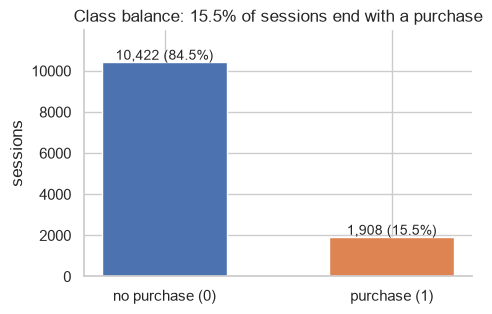

In [6]:
counts = df['revenue'].value_counts()
share = df['revenue'].value_counts(normalize=True)
print(pd.DataFrame({'sessions': counts, 'share': share.round(4)}))

fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(['no purchase (0)', 'purchase (1)'], counts.values, color=[C_NO, C_YES], width=0.55)
for b, n, s in zip(bars, counts.values, share.values):
    ax.text(b.get_x() + b.get_width() / 2, n + 120, f'{n:,} ({s:.1%})', ha='center', fontsize=10)
ax.set_ylabel('sessions')
ax.set_ylim(0, counts.max() * 1.15)
ax.set_title('Class balance: 15.5% of sessions end with a purchase')
sns.despine(fig)
plt.show()

## 4. Numeric feature distributions

All duration and page-count features are strongly right-skewed with heavy tails —
`productrelated_duration` reaches ~64,000 seconds (about 18 hours in one session).
We keep the values as-is: tree-based models are insensitive to monotone transforms, and the
linear model gets standardized features.

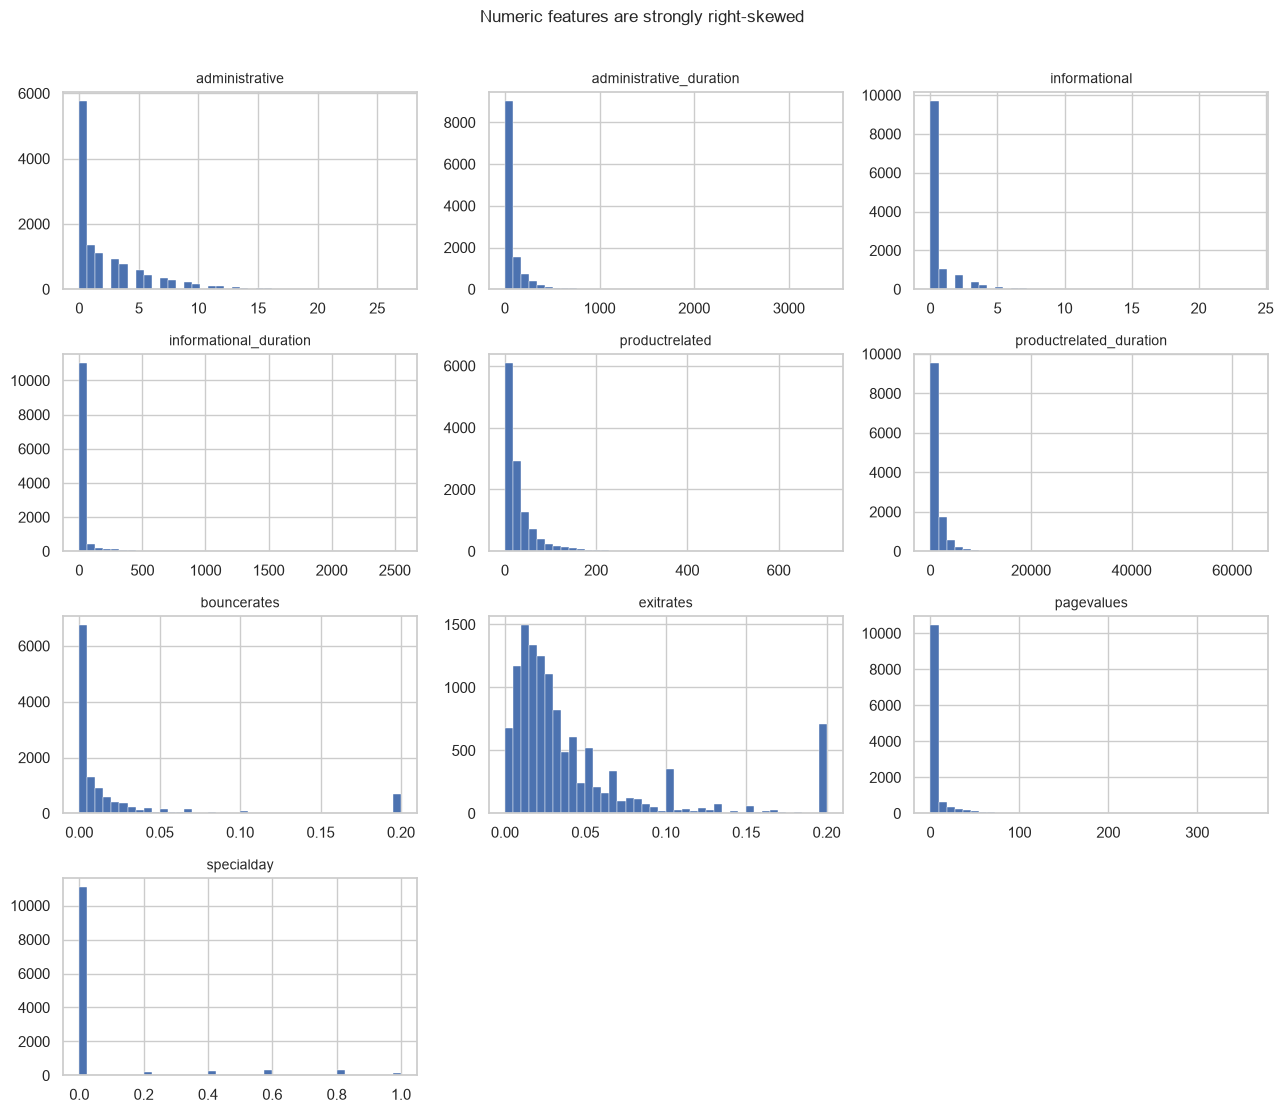

In [7]:
numeric_raw = ['administrative', 'administrative_duration', 'informational', 'informational_duration',
               'productrelated', 'productrelated_duration', 'bouncerates', 'exitrates',
               'pagevalues', 'specialday']

fig, axes = plt.subplots(4, 3, figsize=(13, 11))
for ax, col in zip(axes.flat, numeric_raw):
    ax.hist(df[col], bins=40, color=C_NO, edgecolor='white', linewidth=0.3)
    ax.set_title(col, fontsize=10)
axes.flat[-1].axis('off')
axes.flat[-2].axis('off')
fig.suptitle('Numeric features are strongly right-skewed', y=1.01, fontsize=12)
plt.tight_layout()
plt.show()

## 5. Features vs the target

Purchase rate by category for the main categorical features, with the overall 15.5% base rate
drawn for reference. November and October convert far above average; new visitors convert at
~2x the rate of returning ones; traffic types differ strongly.

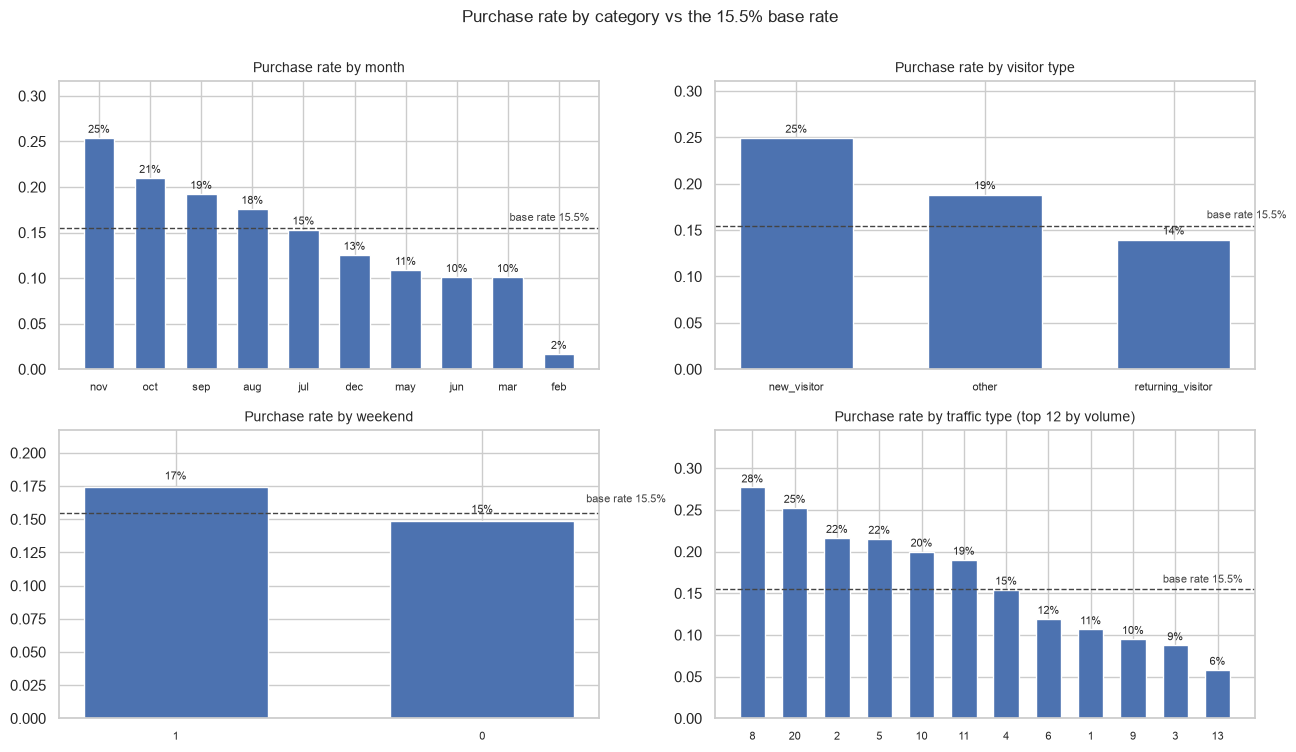

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
base = df['revenue'].mean()

panels = [
    ('month', 'Purchase rate by month'),
    ('visitortype', 'Purchase rate by visitor type'),
    ('weekend', 'Purchase rate by weekend'),
    ('traffictype', 'Purchase rate by traffic type (top 12 by volume)'),
]
for ax, (col, title) in zip(axes.flat, panels):
    order = df[col].value_counts().index[:12]
    rates = df[df[col].isin(order)].groupby(col)['revenue'].mean().reindex(order).sort_values(ascending=False)
    ax.bar(rates.index.astype(str), rates.values, color=C_NO, width=0.6)
    ax.axhline(base, color='#444444', linestyle='--', linewidth=1)
    ax.text(len(rates) - 0.4, base + 0.008, f'base rate {base:.1%}', fontsize=8, ha='right', color='#444444')
    for i, v in enumerate(rates.values):
        ax.text(i, v + 0.006, f'{v:.0%}', ha='center', fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, max(rates.max(), base) * 1.25)
    ax.tick_params(axis='x', labelsize=8)
fig.suptitle('Purchase rate by category vs the 15.5% base rate', y=1.0, fontsize=12)
plt.tight_layout()
plt.show()

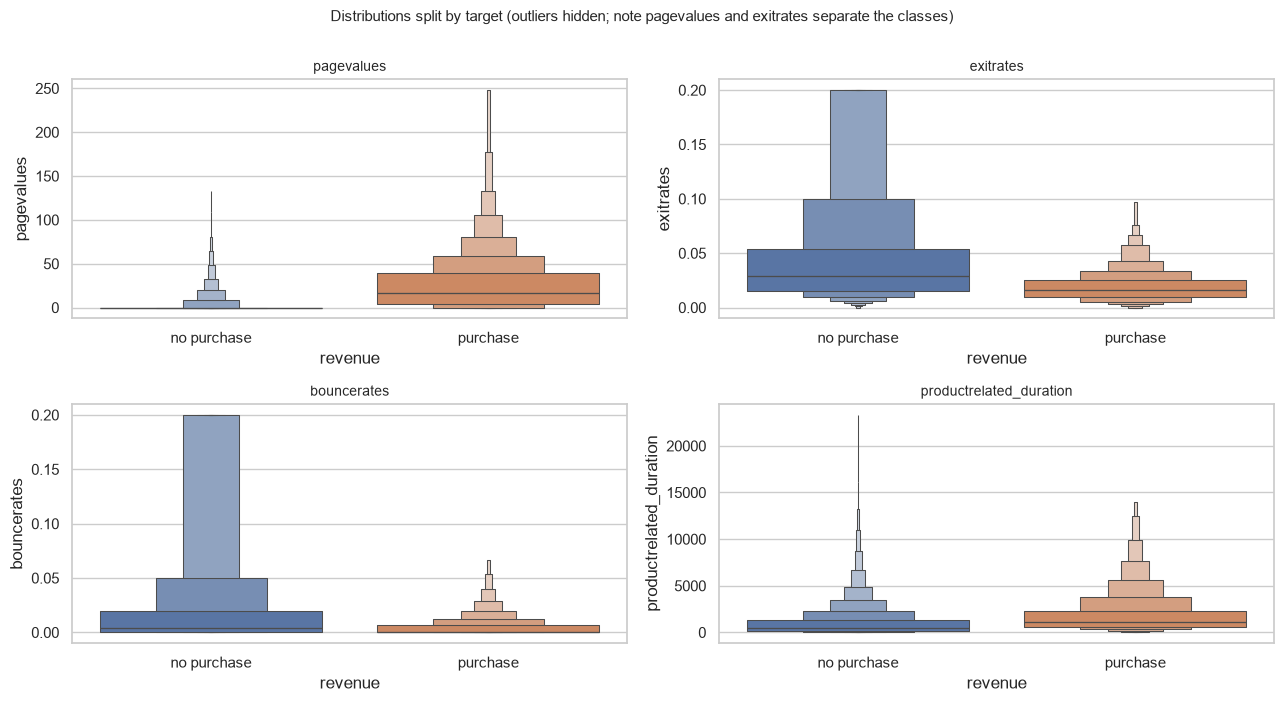

In [9]:
focus = ['pagevalues', 'exitrates', 'bouncerates', 'productrelated_duration']
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, col in zip(axes.flat, focus):
    sns.boxenplot(data=df, x='revenue', y=col, hue='revenue', palette=CLASS_PALETTE,
                  legend=False, ax=ax, showfliers=False)
    ax.set_xticks([0, 1], ['no purchase', 'purchase'])
    ax.set_title(col, fontsize=10)
fig.suptitle('Distributions split by target (outliers hidden; note pagevalues and exitrates separate the classes)',
             y=1.0, fontsize=11)
plt.tight_layout()
plt.show()

## 6. Correlations between numeric features

`bouncerates` and `exitrates` are nearly collinear (they measure overlapping behavior), and the
page-count features correlate with their durations, as expected. No pair is redundant enough to
require dropping a feature — tree ensembles are unaffected, and the linear model tolerates it.

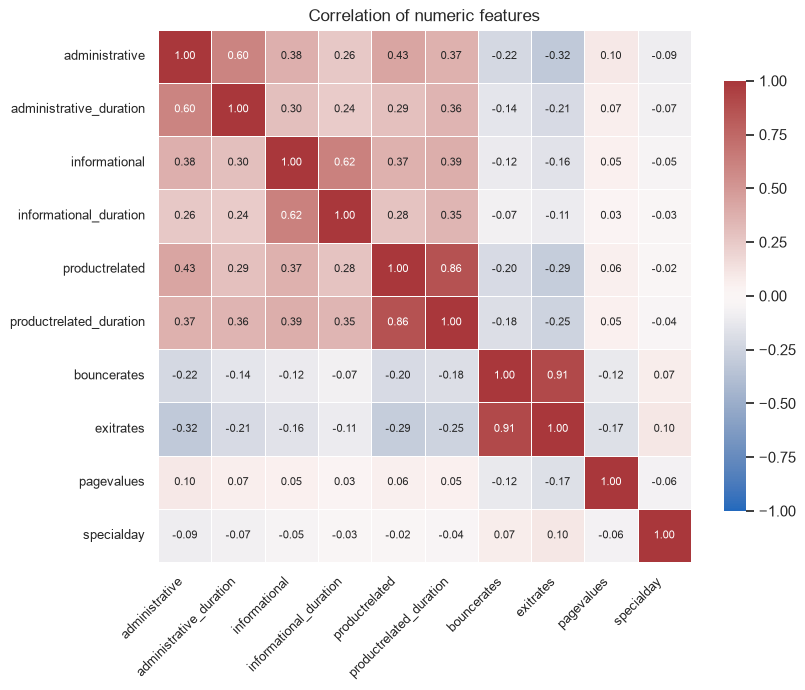

In [10]:
corr = df[numeric_raw].corr()

plt.figure(figsize=(8.5, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8},
            annot_kws={'size': 8})
plt.title('Correlation of numeric features', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

## 7. Feature importance

Two course-standard views before any modeling:

- **Mutual information** between each categorical feature and the target.
- **Correlation with the target** for numeric features — plus, because correlation alone hides
  *inverted* relationships (`exitrates` falls as purchase probability rises), we also compute
  each numeric feature's **single-feature ROC AUC** and symmetrize it with `max(auc, 1 - auc)`.

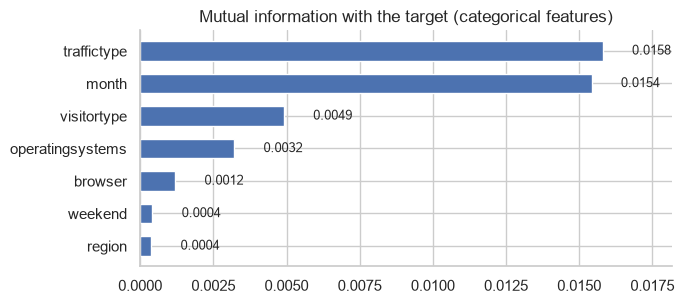

In [11]:
cat_for_mi = ['month', 'operatingsystems', 'browser', 'region', 'traffictype', 'visitortype', 'weekend']
mi = {c: mutual_info_score(df[c], df['revenue']) for c in cat_for_mi}
mi = pd.Series(mi).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(mi.index, mi.values, color=C_NO, height=0.6)
for i, v in enumerate(mi.values):
    ax.text(v + 0.001, i, f'{v:.4f}', va='center', fontsize=9)
ax.set_title('Mutual information with the target (categorical features)')
ax.set_xlim(0, mi.max() * 1.15)
sns.despine(fig)
plt.tight_layout()
plt.show()

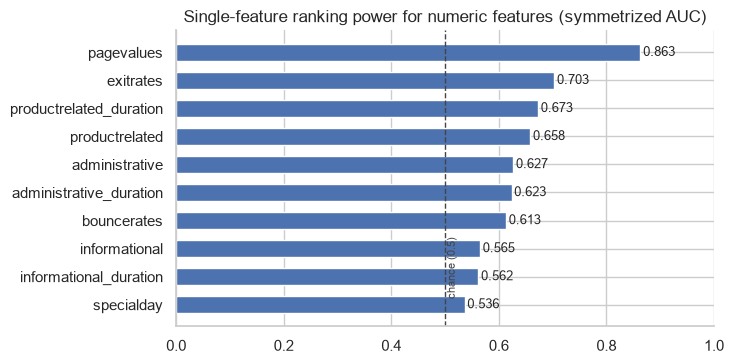

In [12]:
y_all = df['revenue'].values
rows = []
for col in numeric_raw:
    auc = roc_auc_score(y_all, df[col].values)
    rows.append({'feature': col,
                 'corr_with_target': df[col].corr(df['revenue']),
                 'single_feature_auc': auc,
                 'auc_symmetric': max(auc, 1 - auc)})
importance_num = pd.DataFrame(rows).sort_values('auc_symmetric', ascending=False).reset_index(drop=True)
importance_num.round(4)

order = importance_num.sort_values('auc_symmetric')
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(order['feature'], order['auc_symmetric'], color=C_NO, height=0.6)
for i, v in enumerate(order['auc_symmetric'].values):
    ax.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=9)
ax.axvline(0.5, color='#444444', linestyle='--', linewidth=1)
ax.text(0.503, 0.2, 'chance (0.5)', fontsize=8, color='#444444', rotation=90, va='bottom')
ax.set_title('Single-feature ranking power for numeric features (symmetrized AUC)')
ax.set_xlim(0, 1.0)
sns.despine(fig)
plt.tight_layout()
plt.show()

## 8. The `PageValues` question — report with and without it

`pagevalues` is by far the strongest feature: its **single-feature AUC is ~0.86**, and
**88.6% of non-purchase sessions have `pagevalues = 0`, versus only 19.4% of purchase sessions**.
It is a Google Analytics metric: the average transaction value of the pages the visitor saw
before completing a purchase. Two problems with relying on it:

1. **It makes the problem artificially easy.** A model can lean on it as a near-proxy for the label.
2. **It is questionable for the live use case.** The business case (see
   `project-info/business-case.md`) requires scoring a session *partway through browsing*, and
   `pagevalues` is defined retrospectively around completed transactions.

So we will **evaluate every model twice — with and without `pagevalues`** — and decide with this
rule, stated before seeing the results:

> **Ship the model without `pagevalues` if its tuned CV AUC stays at 0.85 or above.**
> That keeps the service deployable for the mid-session use case; the with-`pagevalues` score is
> reported as an upper bound.

         share_zero   mean  median     max
revenue                                   
0             0.886   1.98    0.00  246.76
1             0.194  27.26   16.76  361.76


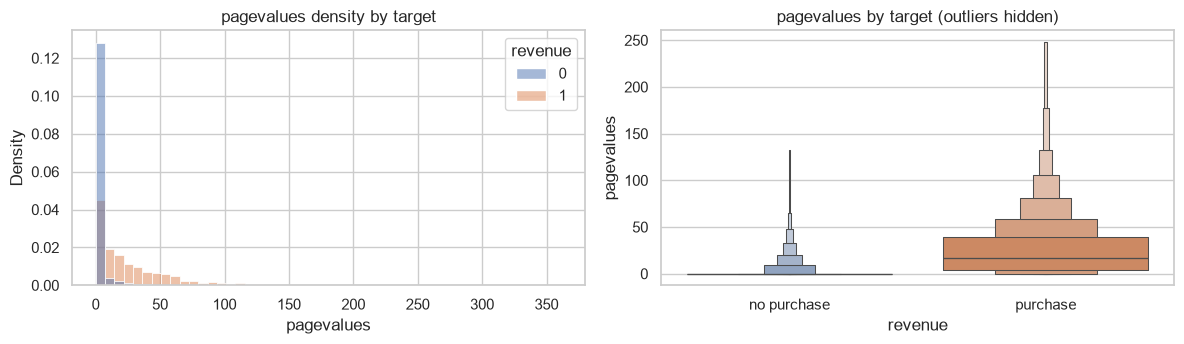

In [13]:
zeros = df.groupby('revenue')['pagevalues'].apply(lambda s: (s == 0).mean())
stats = df.groupby('revenue')['pagevalues'].agg(['mean', 'median', 'max']).round(2)
print(pd.DataFrame({'share_zero': zeros.round(3)}).join(stats))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
sns.histplot(data=df, x='pagevalues', hue='revenue', palette=CLASS_PALETTE, bins=50,
             stat='density', common_norm=False, ax=axes[0])
axes[0].set_title('pagevalues density by target')
sns.boxenplot(data=df, x='revenue', y='pagevalues', hue='revenue', palette=CLASS_PALETTE,
              legend=False, ax=axes[1], showfliers=False)
axes[1].set_xticks([0, 1], ['no purchase', 'purchase'])
axes[1].set_title('pagevalues by target (outliers hidden)')
plt.tight_layout()
plt.show()

## 9. Stratified train/test split

Following `project-info/class-imbalance-note.md`: a stratified **80/20** split. The 20% test set
is touched exactly once, at the end. Model comparison and tuning run as stratified 5-fold CV on
the 80% — a single 20% validation slice would contain only ~380 positives, too noisy to rank models.
The target is extracted immediately and deleted from the feature frames to avoid leakage.

In [14]:
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=RANDOM_STATE, stratify=df['revenue'])

df_full_train = df_full_train.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_full_train['revenue'].values
y_test = df_test['revenue'].values
df_train = df_full_train.drop(columns=['revenue'])
df_test = df_test.drop(columns=['revenue'])

print(f'train: {len(df_train)} rows, positives {y_train.mean():.4f}')
print(f'test:  {len(df_test)} rows, positives {y_test.mean():.4f}')

train: 9864 rows, positives 0.1547
test:  2466 rows, positives 0.1549


## 10. Model comparison protocol

All four models from the course are compared with the same protocol:

- Features: 6 one-hot encoded categoricals + 10 numerics via `DictVectorizer`.
- **Stratified 5-fold CV** on the training set (seed 42), scoring ROC AUC.
- **Preprocessing is fitted inside each fold** (vectorizer, and a scaler for logistic regression),
  so no fold ever sees held-out-fold statistics — the leakage rule from
  `project-info/class-imbalance-note.md`.
- Models start at **default** settings; tuning follows in section 11.

In [15]:
categorical_cols = ['month', 'operatingsystems', 'browser', 'region', 'traffictype', 'visitortype']
numeric_cols = ['administrative', 'administrative_duration', 'informational', 'informational_duration',
                'productrelated', 'productrelated_duration', 'bouncerates', 'exitrates',
                'specialday', 'weekend']
numeric_cols_full = numeric_cols + ['pagevalues']


def to_dicts(frame, num_features):
    return frame[categorical_cols + num_features].to_dict(orient='records')


def cv_auc(make_model, num_features, use_scaler=False, n_splits=5, collect_oof=False):
    """Stratified k-fold CV; preprocessing fitted per fold. Returns per-fold AUCs (and OOF probs)."""
    kfold = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    aucs, oof = [], np.full(len(df_train), np.nan)
    for tr_idx, va_idx in kfold.split(df_train, y_train):
        d_tr, d_va = df_train.iloc[tr_idx], df_train.iloc[va_idx]
        y_tr, y_va = y_train[tr_idx], y_train[va_idx]
        dv = DictVectorizer(sparse=False)
        X_tr = dv.fit_transform(to_dicts(d_tr, num_features))
        X_va = dv.transform(to_dicts(d_va, num_features))
        if use_scaler:
            scaler = StandardScaler()
            X_tr = scaler.fit_transform(X_tr)
            X_va = scaler.transform(X_va)
        model = make_model()
        model.fit(X_tr, y_tr)
        p = model.predict_proba(X_va)[:, 1]
        aucs.append(roc_auc_score(y_va, p))
        if collect_oof:
            oof[va_idx] = p
    aucs = np.array(aucs)
    return (aucs, oof) if collect_oof else aucs


def default_models():
    return {
        'logistic_regression': (
            lambda: LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), True),
        'decision_tree': (
            lambda: DecisionTreeClassifier(random_state=RANDOM_STATE), False),
        'random_forest': (
            lambda: RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), False),
        'xgboost': (
            lambda: XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1,
                                  eval_metric='logloss'), False),
    }

In [16]:
results = {}
for name, (factory, needs_scaler) in default_models().items():
    aucs = cv_auc(factory, numeric_cols_full, use_scaler=needs_scaler)
    results[name] = (aucs.mean(), aucs.std())

default_table = pd.DataFrame(results, index=['auc_mean', 'auc_std']).T.round(4)
print('Default hyperparameters, full features (with pagevalues):')
print(default_table.to_string())
print()
print(f'baseline to beat: always predict "no purchase" -> accuracy {1 - y_train.mean():.3f}, AUC 0.5')

Default hyperparameters, full features (with pagevalues):
                     auc_mean  auc_std
logistic_regression    0.8913   0.0070
decision_tree          0.7367   0.0091
random_forest          0.9243   0.0048
xgboost                0.9253   0.0043

baseline to beat: always predict "no purchase" -> accuracy 0.845, AUC 0.5


## 11. Tuning

A small, documented search per model, always scored with the same 5-fold CV on the training set.
Two-stage searches keep the grid readable: the strongest knob first, then the regularization
knobs at the best value of the first.

In [17]:
# --- logistic regression: C
rows = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    aucs = cv_auc(lambda C=C: LogisticRegression(C=C, max_iter=2000, random_state=RANDOM_STATE),
                  numeric_cols_full, use_scaler=True)
    rows.append({'C': C, 'auc_mean': aucs.mean(), 'auc_std': aucs.std()})
lr_tune = pd.DataFrame(rows).sort_values('auc_mean', ascending=False)
best_C = lr_tune.iloc[0]['C']
print(lr_tune.round(4).to_string(index=False))
print(f'\nbest C = {best_C}  (auc {lr_tune.iloc[0]["auc_mean"]:.4f})')

      C  auc_mean  auc_std
  0.010    0.8920   0.0064
  0.100    0.8920   0.0068
  1.000    0.8913   0.0070
 10.000    0.8912   0.0071
100.000    0.8912   0.0072
  0.001    0.8797   0.0061

best C = 0.01  (auc 0.8920)


In [18]:
# --- decision tree: max_depth, then min_samples_leaf
rows = []
for depth in range(1, 16):
    aucs = cv_auc(lambda depth=depth: DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE),
                  numeric_cols_full)
    rows.append({'max_depth': depth, 'auc_mean': aucs.mean(), 'auc_std': aucs.std()})
dt_depth = pd.DataFrame(rows).sort_values('auc_mean', ascending=False)
best_depth = int(dt_depth.iloc[0]['max_depth'])
print('stage 1 - max_depth:')
print(dt_depth.head(5).round(4).to_string(index=False))
print(f'best max_depth = {best_depth}\n')

rows = []
for leaf in [1, 2, 3, 5, 10, 15, 20, 50, 100]:
    aucs = cv_auc(lambda leaf=leaf: DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=leaf,
                                                           random_state=RANDOM_STATE),
                  numeric_cols_full)
    rows.append({'min_samples_leaf': leaf, 'auc_mean': aucs.mean(), 'auc_std': aucs.std()})
dt_leaf = pd.DataFrame(rows).sort_values('auc_mean', ascending=False)
best_leaf = int(dt_leaf.iloc[0]['min_samples_leaf'])
print('stage 2 - min_samples_leaf at best depth:')
print(dt_leaf.round(4).to_string(index=False))
print(f'\nbest: max_depth={best_depth}, min_samples_leaf={best_leaf}  (auc {dt_leaf.iloc[0]["auc_mean"]:.4f})')

stage 1 - max_depth:
 max_depth  auc_mean  auc_std
         5    0.9125   0.0048
         4    0.9116   0.0055
         6    0.9053   0.0043
         3    0.9036   0.0079
         2    0.8937   0.0053
best max_depth = 5



stage 2 - min_samples_leaf at best depth:
 min_samples_leaf  auc_mean  auc_std
              100    0.9202   0.0062
               50    0.9199   0.0062
               20    0.9150   0.0057
                5    0.9137   0.0039
                3    0.9126   0.0034
                1    0.9125   0.0048
               10    0.9124   0.0045
               15    0.9121   0.0048
                2    0.9121   0.0051

best: max_depth=5, min_samples_leaf=100  (auc 0.9202)


In [19]:
# --- random forest: n_estimators, then max_depth x min_samples_leaf
rows = []
for n in [10, 20, 40, 60, 80, 100, 150, 200]:
    aucs = cv_auc(lambda n=n: RandomForestClassifier(n_estimators=n, random_state=RANDOM_STATE, n_jobs=-1),
                  numeric_cols_full)
    rows.append({'n_estimators': n, 'auc_mean': aucs.mean(), 'auc_std': aucs.std()})
rf_n = pd.DataFrame(rows).sort_values('auc_mean', ascending=False)
best_n = int(rf_n.iloc[0]['n_estimators'])
print('stage 1 - n_estimators:')
print(rf_n.round(4).to_string(index=False))
print(f'best n_estimators = {best_n}\n')

rows = []
for depth in [3, 5, 7, 10, 15, 20]:
    for leaf in [1, 3, 5, 10, 20]:
        aucs = cv_auc(lambda depth=depth, leaf=leaf: RandomForestClassifier(
            n_estimators=best_n, max_depth=depth, min_samples_leaf=leaf,
            random_state=RANDOM_STATE, n_jobs=-1),
            numeric_cols_full)
        rows.append({'max_depth': depth, 'min_samples_leaf': leaf,
                     'auc_mean': aucs.mean(), 'auc_std': aucs.std()})
rf_depth_leaf = pd.DataFrame(rows).sort_values('auc_mean', ascending=False)
best_rf_depth = int(rf_depth_leaf.iloc[0]['max_depth'])
best_rf_leaf = int(rf_depth_leaf.iloc[0]['min_samples_leaf'])
print('stage 2 - max_depth x min_samples_leaf (top 10 of 30):')
print(rf_depth_leaf.head(10).round(4).to_string(index=False))
print(f'\nbest: n_estimators={best_n}, max_depth={best_rf_depth}, min_samples_leaf={best_rf_leaf}'
      f'  (auc {rf_depth_leaf.iloc[0]["auc_mean"]:.4f})')

stage 1 - n_estimators:
 n_estimators  auc_mean  auc_std
          200    0.9260   0.0041
          150    0.9251   0.0040
          100    0.9243   0.0048
           80    0.9233   0.0053
           60    0.9211   0.0054
           40    0.9182   0.0056
           20    0.9072   0.0080
           10    0.8857   0.0060
best n_estimators = 200



stage 2 - max_depth x min_samples_leaf (top 10 of 30):
 max_depth  min_samples_leaf  auc_mean  auc_std
        20                 3    0.9288   0.0034
        15                 3    0.9287   0.0041
        15                 5    0.9283   0.0043
        20                 5    0.9281   0.0038
        20                10    0.9276   0.0043
        15                10    0.9266   0.0044
        15                 1    0.9266   0.0056
        20                 1    0.9262   0.0059
        10                 5    0.9259   0.0044
        10                10    0.9257   0.0053

best: n_estimators=200, max_depth=20, min_samples_leaf=3  (auc 0.9288)


In [20]:
# --- xgboost: eta, max_depth, min_child_weight, then number of rounds (sequential)
best_xgb = {'n_estimators': 100}

rows = []
for eta in [0.01, 0.05, 0.1, 0.2, 0.3]:
    aucs = cv_auc(lambda eta=eta: XGBClassifier(learning_rate=eta, random_state=RANDOM_STATE,
                                                n_jobs=-1, eval_metric='logloss'),
                  numeric_cols_full)
    rows.append({'eta': eta, 'auc_mean': aucs.mean(), 'auc_std': aucs.std()})
xgb_eta = pd.DataFrame(rows).sort_values('auc_mean', ascending=False)
best_xgb['learning_rate'] = float(xgb_eta.iloc[0]['eta'])
print('stage 1 - eta:'); print(xgb_eta.round(4).to_string(index=False)); print()

rows = []
for depth in [2, 3, 4, 5, 6, 8]:
    aucs = cv_auc(lambda depth=depth: XGBClassifier(learning_rate=best_xgb['learning_rate'],
                                                    max_depth=depth, random_state=RANDOM_STATE,
                                                    n_jobs=-1, eval_metric='logloss'),
                  numeric_cols_full)
    rows.append({'max_depth': depth, 'auc_mean': aucs.mean(), 'auc_std': aucs.std()})
xgb_depth = pd.DataFrame(rows).sort_values('auc_mean', ascending=False)
best_xgb['max_depth'] = int(xgb_depth.iloc[0]['max_depth'])
print(f'stage 2 - max_depth at eta={best_xgb["learning_rate"]}:')
print(xgb_depth.round(4).to_string(index=False)); print()

rows = []
for mcw in [1, 2, 5, 10, 20]:
    aucs = cv_auc(lambda mcw=mcw: XGBClassifier(learning_rate=best_xgb['learning_rate'],
                                                max_depth=best_xgb['max_depth'], min_child_weight=mcw,
                                                random_state=RANDOM_STATE, n_jobs=-1,
                                                eval_metric='logloss'),
                  numeric_cols_full)
    rows.append({'min_child_weight': mcw, 'auc_mean': aucs.mean(), 'auc_std': aucs.std()})
xgb_mcw = pd.DataFrame(rows).sort_values('auc_mean', ascending=False)
best_xgb['min_child_weight'] = int(xgb_mcw.iloc[0]['min_child_weight'])
print(f'stage 3 - min_child_weight:'); print(xgb_mcw.round(4).to_string(index=False)); print()

rows = []
for n in [50, 100, 150, 200, 300, 400]:
    aucs = cv_auc(lambda n=n: XGBClassifier(learning_rate=best_xgb['learning_rate'],
                                            max_depth=best_xgb['max_depth'],
                                            min_child_weight=best_xgb['min_child_weight'],
                                            n_estimators=n, random_state=RANDOM_STATE,
                                            n_jobs=-1, eval_metric='logloss'),
                  numeric_cols_full)
    rows.append({'n_estimators': n, 'auc_mean': aucs.mean(), 'auc_std': aucs.std()})
xgb_n = pd.DataFrame(rows).sort_values('auc_mean', ascending=False)
best_xgb['n_estimators'] = int(xgb_n.iloc[0]['n_estimators'])
print('stage 4 - n_estimators:'); print(xgb_n.round(4).to_string(index=False))
print(f'\nbest xgboost params: {best_xgb}  (auc {xgb_n.iloc[0]["auc_mean"]:.4f})')

stage 1 - eta:
 eta  auc_mean  auc_std
0.05    0.9330   0.0049
0.10    0.9317   0.0047
0.01    0.9300   0.0052
0.20    0.9278   0.0042
0.30    0.9253   0.0043



stage 2 - max_depth at eta=0.05:
 max_depth  auc_mean  auc_std
         4    0.9337   0.0036
         5    0.9335   0.0041
         3    0.9334   0.0038
         6    0.9330   0.0049
         8    0.9318   0.0043
         2    0.9286   0.0035



stage 3 - min_child_weight:
 min_child_weight  auc_mean  auc_std
               10    0.9350   0.0037
               20    0.9346   0.0042
                5    0.9343   0.0036
                2    0.9342   0.0035
                1    0.9337   0.0036



stage 4 - n_estimators:
 n_estimators  auc_mean  auc_std
          100    0.9350   0.0037
          150    0.9347   0.0037
          200    0.9342   0.0037
           50    0.9339   0.0039
          300    0.9336   0.0038
          400    0.9326   0.0038

best xgboost params: {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 10}  (auc 0.9350)


In [21]:
def tuned_factories(features, scale_pos_weight=None):
    return {
        'logistic_regression': (
            lambda: LogisticRegression(C=best_C, max_iter=2000, random_state=RANDOM_STATE), True),
        'decision_tree': (
            lambda: DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=best_leaf,
                                           random_state=RANDOM_STATE), False),
        'random_forest': (
            lambda: RandomForestClassifier(n_estimators=best_n, max_depth=best_rf_depth,
                                           min_samples_leaf=best_rf_leaf,
                                           random_state=RANDOM_STATE, n_jobs=-1), False),
        'xgboost': (
            lambda: XGBClassifier(**{**best_xgb, 'scale_pos_weight': scale_pos_weight}
                                  if scale_pos_weight else best_xgb,
                                  random_state=RANDOM_STATE, n_jobs=-1, eval_metric='logloss'), False),
    }

tuned_table = {}
for name, (factory, needs_scaler) in tuned_factories(numeric_cols_full).items():
    aucs = cv_auc(factory, numeric_cols_full, use_scaler=needs_scaler)
    tuned_table[name] = aucs.mean()

summary = pd.DataFrame({
    'default_auc': {k: v[0] for k, v in results.items()},
    'tuned_auc': tuned_table,
}).round(4)
summary['params'] = [
    f'C={best_C}',
    f'max_depth={best_depth}, min_samples_leaf={best_leaf}',
    f'n_estimators={best_n}, max_depth={best_rf_depth}, min_samples_leaf={best_rf_leaf}',
    str(best_xgb),
]
print('Summary - default vs tuned (full features, 5-fold stratified CV):')
print(summary[['default_auc', 'tuned_auc']].to_string())
print()
best_name = summary['tuned_auc'].idxmax()
print(f'provisional best model: {best_name} ({summary.loc[best_name, "tuned_auc"]:.4f})')

Summary - default vs tuned (full features, 5-fold stratified CV):
                     default_auc  tuned_auc
logistic_regression       0.8913     0.8920
decision_tree             0.7367     0.9202
random_forest             0.9243     0.9288
xgboost                   0.9253     0.9350

provisional best model: xgboost (0.9350)


## 12. The experiment: with vs without `pagevalues`

Every tuned model is re-evaluated without `pagevalues` under the identical CV protocol, and the
section-8 rule decides which feature set ships: **without `pagevalues` if it holds AUC ≥ 0.85**.

In [22]:
rows = []
for name, (factory, needs_scaler) in tuned_factories(numeric_cols_full).items():
    with_pv = cv_auc(factory, numeric_cols_full, use_scaler=needs_scaler)
    without_pv = cv_auc(factory, numeric_cols, use_scaler=needs_scaler)
    rows.append({'model': name,
                 'auc_with_pagevalues': with_pv.mean(),
                 'auc_without_pagevalues': without_pv.mean(),
                 'gap': with_pv.mean() - without_pv.mean()})
ablation = pd.DataFrame(rows).set_index('model').round(4)
print(ablation.to_string())

best_no_pv = ablation['auc_without_pagevalues'].max()
best_no_pv_name = ablation['auc_without_pagevalues'].idxmax()
if best_no_pv >= 0.85:
    num_features_final = numeric_cols
    final_decision = (f"DECISION: ship WITHOUT pagevalues. Best without = {best_no_pv_name} "
                      f"({best_no_pv:.4f} >= 0.85); with-pagevalues scores are reported as the ceiling.")
else:
    num_features_final = numeric_cols_full
    final_decision = (f"DECISION: keep pagevalues. Best without = {best_no_pv_name} "
                      f"({best_no_pv:.4f} < 0.85), so the mid-session use case would not be served well enough.")
print()
print(final_decision)

                     auc_with_pagevalues  auc_without_pagevalues     gap
model                                                                   
logistic_regression               0.8920                  0.7468  0.1452
decision_tree                     0.9202                  0.7483  0.1719
random_forest                     0.9288                  0.7860  0.1429
xgboost                           0.9350                  0.7819  0.1531

DECISION: keep pagevalues. Best without = random_forest (0.7860 < 0.85), so the mid-session use case would not be served well enough.


## 13. Class-weight check

With 15.5% positives we try the course-standard weighting options (`class_weight='balanced'` for
the linear model and forest, `scale_pos_weight` for XGBoost) on the **final feature set**. Weights
mostly shift probabilities, not ranking, so we keep them only if CV AUC actually improves —
and the rule applies to **the model we ship** (the best-tuned model from section 11), not to any
individual model: an improvement on a model we do not deploy changes nothing.

In [23]:
n_pos = y_train.sum()
n_neg = len(y_train) - n_pos
spw = n_neg / n_pos
print(f'scale_pos_weight for this data: {spw:.2f}\n')

fac, scaler_needed = tuned_factories(num_features_final)['xgboost']
auc_plain = cv_auc(fac, num_features_final)
auc_weighted = cv_auc(lambda: XGBClassifier(**best_xgb, scale_pos_weight=spw,
                                            random_state=RANDOM_STATE, n_jobs=-1,
                                            eval_metric='logloss'),
                      num_features_final)

fac_lr, scaler_lr = tuned_factories(num_features_final)['logistic_regression']
auc_lr = cv_auc(fac_lr, num_features_final, use_scaler=scaler_lr)
auc_lr_bal = cv_auc(lambda: LogisticRegression(C=best_C, max_iter=2000, class_weight='balanced',
                                               random_state=RANDOM_STATE),
                    num_features_final, use_scaler=scaler_lr)

fac_rf, _ = tuned_factories(num_features_final)['random_forest']
auc_rf = cv_auc(fac_rf, num_features_final)
auc_rf_bal = cv_auc(lambda: RandomForestClassifier(n_estimators=best_n, max_depth=best_rf_depth,
                                                   min_samples_leaf=best_rf_leaf,
                                                   class_weight='balanced',
                                                   random_state=RANDOM_STATE, n_jobs=-1),
                    num_features_final)

weights_table = pd.DataFrame({
    'plain': {'logistic_regression': auc_lr.mean(), 'random_forest': auc_rf.mean(), 'xgboost': auc_plain.mean()},
    'weighted': {'logistic_regression': auc_lr_bal.mean(), 'random_forest': auc_rf_bal.mean(),
                 'xgboost': auc_weighted.mean()},
}).round(4)
print(weights_table.to_string())
gains = weights_table['weighted'] - weights_table['plain']
final_gain = gains[best_name]
print()
print('per-model improvement from weighting:')
print(gains.round(4).to_string())
print()
print(f'improvement from weighting for the final model ({best_name}): {final_gain:+.4f}')
print('DECISION: keep the final model unweighted; the decision threshold (section 14) handles the imbalance.'
      if final_gain < 0.002 else
      'DECISION: weighting helps the final model; use it in train.py and note it in the README.')

scale_pos_weight for this data: 5.46



                      plain  weighted
logistic_regression  0.8920    0.8975
random_forest        0.9288    0.9296
xgboost              0.9350    0.9352

per-model improvement from weighting:
logistic_regression    0.0055
random_forest          0.0008
xgboost                0.0002

improvement from weighting for the final model (xgboost): +0.0002
DECISION: keep the final model unweighted; the decision threshold (section 14) handles the imbalance.


## 14. Choosing the decision threshold from business costs

Following `project-info/business-case.md`, the intervention is a proactive chat invite or a small
nudge. We state the cost assumption explicitly and choose the threshold that minimizes expected
cost on **out-of-fold** predictions (every prediction below comes from a model that never saw the
session it scored):

- **False positive** (agent/offer spent on a non-buyer): cost **1**.
- **False negative** (high-intent visitor left alone and lost): cost **5** — a lost order is worth
  several wasted invites, but invites are not free and agent capacity is limited.

A sensitivity check at cost ratios 1:1, 3:1 and 10:1 follows.

In [24]:
final_factory, final_scaler = tuned_factories(num_features_final)[best_name]
aucs_oof, oof_probs = cv_auc(final_factory, num_features_final, use_scaler=final_scaler,
                             collect_oof=True)
print(f'{best_name} on final feature set: CV auc {aucs_oof.mean():.4f} ± {aucs_oof.std():.4f}')

FP_COST, FN_COST = 1.0, 5.0
thresholds = np.linspace(0.05, 0.95, 19)
rows = []
for t in thresholds:
    pred = oof_probs >= t
    tp = int((pred & (y_train == 1)).sum())
    fp = int((pred & (y_train == 0)).sum())
    fn = int((~pred & (y_train == 1)).sum())
    precision = tp / (tp + fp) if tp + fp else 1.0
    recall = tp / (tp + fn)
    rows.append({'threshold': round(t, 2), 'precision': precision, 'recall': recall,
                 'interventions_per_1k': round((tp + fp) / len(y_train) * 1000),
                 'cost': fp * FP_COST + fn * FN_COST})
thr_table = pd.DataFrame(rows)
print(thr_table.round(3).to_string(index=False))

xgboost on final feature set: CV auc 0.9350 ± 0.0037
 threshold  precision  recall  interventions_per_1k   cost
      0.05      0.348   0.961                   427 3044.0
      0.10      0.467   0.898                   297 2341.0
      0.15      0.523   0.862                   255 2252.0
      0.20      0.562   0.821                   226 2342.0
      0.25      0.602   0.794                   204 2376.0
      0.30      0.631   0.763                   187 2485.0
      0.35      0.660   0.736                   173 2594.0
      0.40      0.685   0.692                   156 2835.0
      0.45      0.714   0.653                   142 3045.0
      0.50      0.742   0.607                   127 3318.0
      0.55      0.758   0.551                   112 3693.0
      0.60      0.784   0.495                    98 4058.0
      0.65      0.819   0.433                    82 4471.0
      0.70      0.847   0.366                    67 4941.0
      0.75      0.868   0.307                    55 5361.0
   

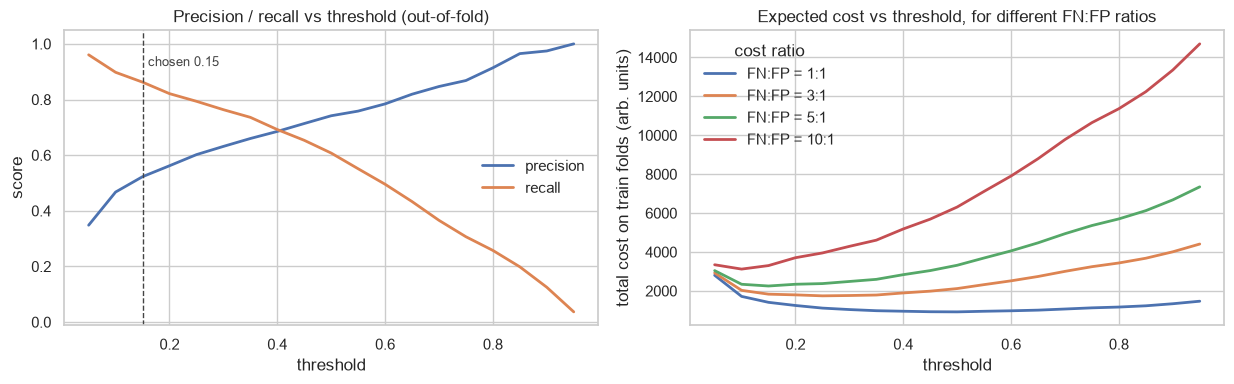

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))

ax = axes[0]
ax.plot(thr_table['threshold'], thr_table['precision'], color=C_NO, linewidth=2, label='precision')
ax.plot(thr_table['threshold'], thr_table['recall'], color=C_YES, linewidth=2, label='recall')
best_row = thr_table.loc[thr_table['cost'].idxmin()]
ax.axvline(best_row['threshold'], color='#444444', linestyle='--', linewidth=1)
ax.text(best_row['threshold'] + 0.01, 0.92, f"chosen {best_row['threshold']:.2f}", fontsize=9, color='#444444')
ax.set_xlabel('threshold'); ax.set_ylabel('score')
ax.set_title('Precision / recall vs threshold (out-of-fold)')
ax.legend(frameon=False)

ax = axes[1]
for ratio in [1, 3, 5, 10]:
    costs = []
    for t in thr_table['threshold']:
        pred = oof_probs >= t
        fp = int((pred & (y_train == 0)).sum())
        fn = int((~pred & (y_train == 1)).sum())
        costs.append(fp * 1.0 + fn * ratio)
    ax.plot(thr_table['threshold'], costs, linewidth=2, label=f'FN:FP = {ratio}:1')
ax.set_xlabel('threshold'); ax.set_ylabel('total cost on train folds (arb. units)')
ax.set_title('Expected cost vs threshold, for different FN:FP ratios')
ax.legend(frameon=False, title='cost ratio')
plt.tight_layout()
plt.show()

In [26]:
print('Sensitivity of the chosen threshold to the cost ratio:')
for ratio in [1, 3, 5, 10]:
    costs = []
    for t in thresholds:
        pred = oof_probs >= t
        fp = int((pred & (y_train == 0)).sum())
        fn = int((~pred & (y_train == 1)).sum())
        costs.append(fp * 1.0 + fn * ratio)
    t_best = thresholds[int(np.argmin(costs))]
    pred = oof_probs >= t_best
    tp = int((pred & (y_train == 1)).sum()); fp = int((pred & (y_train == 0)).sum())
    fn = int((~pred & (y_train == 1)).sum())
    print(f'  FN:FP = {ratio:>2}:1 -> threshold {t_best:.2f} '
          f'(precision {tp / (tp + fp):.3f}, recall {tp / (tp + fn):.3f})')

THRESHOLD = float(best_row['threshold'])
print(f"\nCHOSEN THRESHOLD = {THRESHOLD:.2f}  (cost ratio 5:1)")
print(f"at this threshold on out-of-fold predictions: "
      f"precision {best_row['precision']:.3f}, recall {best_row['recall']:.3f}, "
      f"{int(best_row['interventions_per_1k'])} interventions per 1k sessions")

Sensitivity of the chosen threshold to the cost ratio:
  FN:FP =  1:1 -> threshold 0.50 (precision 0.742, recall 0.607)
  FN:FP =  3:1 -> threshold 0.25 (precision 0.602, recall 0.794)
  FN:FP =  5:1 -> threshold 0.15 (precision 0.523, recall 0.862)
  FN:FP = 10:1 -> threshold 0.10 (precision 0.467, recall 0.898)

CHOSEN THRESHOLD = 0.15  (cost ratio 5:1)
at this threshold on out-of-fold predictions: precision 0.523, recall 0.862, 255 interventions per 1k sessions


## 15. Final model and the single test-set check

The best model is retrained on the full training set (80%) with its tuned parameters and the
chosen feature set, then evaluated **once** on the held-out test set. The test AUC should land
close to the CV estimate; a large drop would signal leakage or overfitting. Note that the tuned
CV estimate is mildly optimistic — the parameters were selected on these same folds — so the
test score is the honest, unbiased number.

In [27]:
dv_full = DictVectorizer(sparse=False)
X_train_final = dv_full.fit_transform(to_dicts(df_train, num_features_final))
X_test_final = dv_full.transform(to_dicts(df_test, num_features_final))

final_model = final_factory()
final_model.fit(X_train_final, y_train)
test_probs = final_model.predict_proba(X_test_final)[:, 1]

test_auc = roc_auc_score(y_test, test_probs)
test_pred = test_probs >= THRESHOLD
tp = int((test_pred & (y_test == 1)).sum()); fp = int((test_pred & (y_test == 0)).sum())
fn = int((~test_pred & (y_test == 1)).sum()); tn = int((~test_pred & (y_test == 0)).sum())

print(f'final model: {best_name}')
print(f'features: {"with" if "pagevalues" in num_features_final else "without"} pagevalues')
print(f'params: {dict(final_model.get_params()) if best_name != "xgboost" else best_xgb}')
print()
print(f'CV estimate (train folds):  {aucs_oof.mean():.4f} ± {aucs_oof.std():.4f}')
print(f'test ROC AUC (single check): {test_auc:.4f}   difference: {abs(test_auc - aucs_oof.mean()):.4f}')
print()
print(f'at threshold {THRESHOLD}:')
print(f'  precision {tp / (tp + fp):.3f}   recall {tp / (tp + fn):.3f}')
print(f'  confusion (test): tp={tp}, fp={fp}, fn={fn}, tn={tn}')
print(f'  interventions: {tp + fp} of {len(y_test)} test sessions '
      f'({(tp + fp) / len(y_test) * 1000:.0f} per 1k)')

final model: xgboost
features: with pagevalues
params: {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 10}

CV estimate (train folds):  0.9350 ± 0.0037
test ROC AUC (single check): 0.9322   difference: 0.0028

at threshold 0.15:
  precision 0.520   recall 0.864
  confusion (test): tp=330, fp=305, fn=52, tn=1779
  interventions: 635 of 2466 test sessions (258 per 1k)


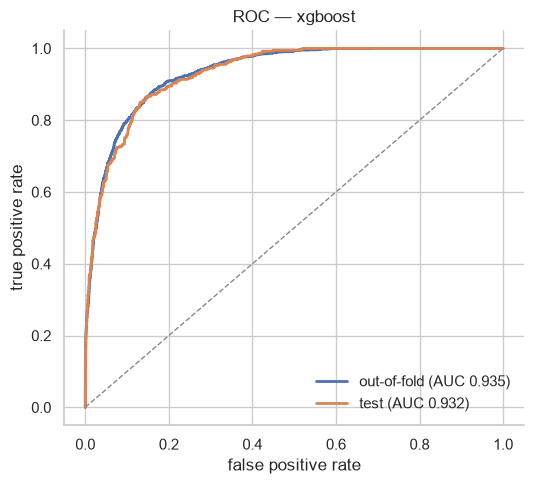

In [28]:
fpr_oof, tpr_oof, _ = roc_curve(y_train, oof_probs)
fpr_te, tpr_te, _ = roc_curve(y_test, test_probs)

plt.figure(figsize=(5.5, 5))
plt.plot(fpr_oof, tpr_oof, color=C_NO, linewidth=2,
         label=f'out-of-fold (AUC {aucs_oof.mean():.3f})')
plt.plot(fpr_te, tpr_te, color=C_YES, linewidth=2,
         label=f'test (AUC {test_auc:.3f})')
plt.plot([0, 1], [0, 1], color='#888888', linestyle='--', linewidth=1)
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.title(f'ROC — {best_name}')
plt.legend(frameon=False, loc='lower right')
sns.despine()
plt.tight_layout()
plt.show()

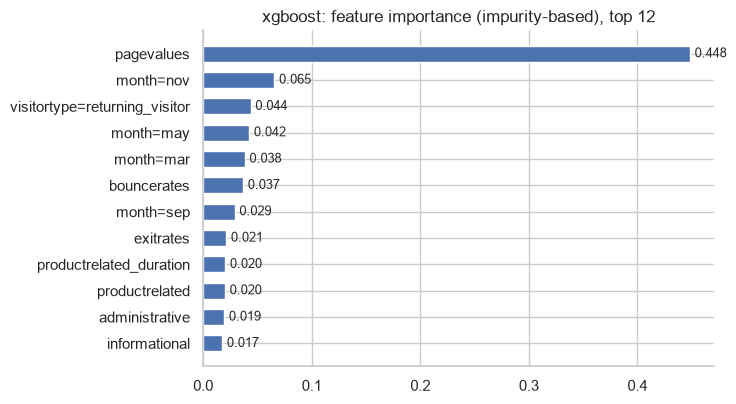

In [29]:
names = dv_full.get_feature_names_out()
if hasattr(final_model, 'feature_importances_'):
    imp = pd.Series(final_model.feature_importances_, index=names)
    label = 'feature importance (impurity-based)'
else:
    imp = pd.Series(np.abs(final_model.coef_[0]), index=names)
    label = 'absolute coefficient value'

top = imp.sort_values().tail(12)
plt.figure(figsize=(7.5, 4.2))
plt.barh(top.index, top.values, color=C_NO, height=0.6)
for i, v in enumerate(top.values):
    plt.text(v + top.max() * 0.01, i, f'{v:.3f}', va='center', fontsize=9)
plt.title(f'{best_name}: {label}, top 12')
sns.despine()
plt.tight_layout()
plt.show()

## 16. Summary

**Final model:** XGBoost (`n_estimators=100, eta=0.05, max_depth=4, min_child_weight=10`),
trained on the 80% training split, evaluated once on the held-out test set.

| | |
|---|---|
| CV ROC AUC (train folds) | 0.9350 ± 0.0037 |
| Test ROC AUC (single check) | 0.9322 |
| Threshold | 0.15 (FN:FP cost ratio 5:1) |
| Test precision / recall at threshold | 0.520 / 0.864 |
| Interventions | ~258 per 1,000 sessions |

**Decisions made and why:**

- **Model:** XGBoost won the 4-model comparison (0.9350 vs RF 0.9288, DT 0.9202, LR 0.8920);
  tuning helped tree models most (DT +0.18, XGB +0.01 over defaults).
- **`pagevalues` stays.** Without it every model falls to 0.75-0.79 AUC (section 12), below the
  pre-stated 0.85 bar. The operational risk of computing it mid-session is documented in the
  README and `project-info/business-case.md`.
- **No class weights:** the decision rule applies to the shipped model, and on the final XGBoost
  `scale_pos_weight` added +0.0002 AUC (noise); the 15.5% imbalance is handled by stratification
  and the cost-based threshold (section 13).
- **Threshold 0.15** follows from assuming a lost sale costs 5x a wasted intervention; the
  sensitivity table (section 14) shows the settings for other cost ratios.
- **Tuning bias:** tuned CV scores were selected on the same folds they are reported on, so they
  are mildly optimistic; the single test-set check is the unbiased confirmation.

`train.py` reproduces this model (identical cleaning, split seed and parameters) and saves
`model.bin`; `predict.py` serves it with the same threshold. The two differ from the notebook
in no computational step.